# 🎬 Netflix Global Content & Expansion Strategy Analysis

---

### 🎯 Selected Project Challenge
**Challenge 2: Global Expansion Strategy**  
> **Core Business Question:** *Which countries contribute the most content to Netflix, and where could Netflix expand next?*

### 📋 Project Overview & Objectives
In an increasingly competitive global streaming landscape, understanding geographic content supply, localization gaps, and regional catalog balance is critical for subscriber growth. Using a realistic, noisy 5,000-record Netflix dataset (`netflix_global_expansion_raw_5000.csv`), our team executes an end-to-end data analytics workflow—from raw data remediation and feature extraction to exploratory analysis, executive visualizations, and actionable expansion recommendations.

---

## Project Team

| No. | Team Member | Role |
|---:|---|---|
| 1 | Ashutosh Shahi | Data Cleaning |
| 2 | Aryan Sutariya | EDA |
| 3 | Mahadev Mishra | Visualization |
| 4 | Monalisa Raut | Final Report |

---

# **-------------Part-1 : Ashutosh Shahi --------------**

### 🛠️ Data Quality Audit & Remediation Plan
Before analyzing global expansion opportunities, the raw 5,000-row dataset (`netflix_global_expansion_raw_5000.csv`) requires systematic cleaning across several data quality issues:
1. **Duplicate & Near-Duplicate Records:** Exact duplicates and case-shifted title duplicates inflate country counts.
2. **Inconsistent Categorical Labels:** `type` contains variants (`Movie`, `movie`, `MOVIE`, `TV-Show`, `Tv show`, `'nan'`); `country` contains aliases (`USA`, `US`, `U.S.A.`, `UK`, `U.K.`, `Great Britain`, `Korea, South`, `Deutschland`, `Brasil`) and mixed delimiters (`,`, `/`, `;`).
3. **Misplaced & Corrupted Values:** Duration strings (`74 min`, `84 min`) appear inside `rating`; invalid years (`-1`, `0`, `1925`, `2099`) appear in `release_year`; HTML tags (`<p>...</p>`) and trailing IDs pollute `description`.
4. **Unstructured Metadata Extraction:** The `unstructured_metadata` column stores heterogeneous strings (`Views~... | IMDb:...`, `region_tier=...; score=...; lang=...`) that must be parsed via regular expressions into structured numeric and categorical features (`estimated_views`, `imdb_score`, `region_tier`).

In [18]:
import pandas as pd
import numpy as np
import re
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

raw_file_path = '../data/netflix_global_expansion_raw_5000.csv'
df_raw = pd.read_csv(raw_file_path)

print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print("\nMissing Values Before Cleaning:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
df_raw.head(5)

Raw Dataset Shape: 5,000 rows x 13 columns

Missing Values Before Cleaning:
type                       49
title                      17
director                 1403
cast                      461
country                   390
date_added                 62
rating                    190
duration                   47
listed_in                  44
description               109
unstructured_metadata    1015
dtype: int64


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,unstructured_metadata
0,s1502,Movie,Silent Madrid 3,"Vikram Kowalski, Mei Novak",Mei Hassan | Liam Nair | Omar Takahashi | Davi...,Indonesia,"September 12, 2025",1991,PG-13,103 min,Horror Movies / Stand-Up Comedy,An intimate look into the vibrant culture and ...,"Views~39,632,495 | IMDb:8.2/10 | Subtitles:EN,..."
1,s2587,Movie,Frozen Paris 6,NaN,"Fatima Khan, Sofia Kim, Rahul Takahashi, Isabe...",NaN,"Dec 24, 2025",2012,TV-PG,80 min,Horror Movies / Comedies,"Set in United Kingdom, a determined architect ...",N/A - pending audit
2,s2654,Movie,Crimson Lagos 6,Claire Chen,Omar Kowalski | Nadia Brown | Jin Kim | Yuki S...,South Korea,"Sep 29, 2019",2017,PG,123 min,"action & adventure, Sports Movies, Independent...",NaN,N/A - pending audit
3,s1056,Movie,Rise of Dreamers 5,NaN,Chloe Hassan; Marcus Nair; Gabriel O'Connor; L...,Poland,"July 31, 2023",2016,TV-14,89 min,"Dramas, Horror Movies","When a sudden crisis strikes Poland, an unlike...",region_tier=Tier-1; score=6.1; lang=English
4,s706,Movie,Rise of Berlin,Noah Dubois,"Claire Kowalski, Gabriel Laurent, Rahul Nair, ...",Thailand,"March 03, 2025",2015,TV-MA,120 min,"Music & Musicals, Stand-Up Comedy","A heartwarming comedy about family, tradition,...",N/A - pending audit


In [19]:
df_clean = df_raw.copy()

df_clean['show_id'] = df_clean['show_id'].astype(str).str.strip().str.lower().str.replace('-', '', regex=False)
df_clean['title'] = (
    df_clean['title']
    .astype(str)
    .replace({'nan': np.nan, 'None': np.nan, '': np.nan})
    .str.strip()
    .str.replace(r'\s*###$', '', regex=True)
)
df_clean = df_clean.dropna(subset=['title']).copy()
df_clean['title_norm'] = df_clean['title'].str.lower().str.strip()
df_clean = df_clean.drop_duplicates(subset=['title_norm'], keep='first').drop(columns=['title_norm'])

def clean_content_type(val):
    if pd.isna(val) or str(val).strip().lower() in ['nan', 'none', '']:
        return np.nan
    s = str(val).strip().lower().replace('-', ' ')
    if 'movie' in s:
        return 'Movie'
    if 'tv' in s or 'show' in s:
        return 'TV Show'
    return np.nan

df_clean['type'] = df_clean['type'].apply(clean_content_type)
mask_missing_type = df_clean['type'].isna()
df_clean.loc[mask_missing_type & df_clean['duration'].astype(str).str.contains('Season', case=False, na=False), 'type'] = 'TV Show'
df_clean['type'] = df_clean['type'].fillna('Movie')

country_alias_map = {
    'usa': 'United States', 'us': 'United States', 'u.s.a.': 'United States', 'united states': 'United States',
    'uk': 'United Kingdom', 'u.k.': 'United Kingdom', 'united kingdom': 'United Kingdom', 'great britain': 'United Kingdom',
    'korea, south': 'South Korea', 's. korea': 'South Korea', 'south korea': 'South Korea',
    'india': 'India', 'can': 'Canada', 'canada': 'Canada',
    'jpn': 'Japan', 'japan': 'Japan',
    'deutschland': 'Germany', 'germany': 'Germany',
    'fra': 'France', 'france': 'France',
    'esp': 'Spain', 'spain': 'Spain',
    'brasil': 'Brazil', 'brazil': 'Brazil',
    'nga': 'Nigeria', 'nigeria': 'Nigeria'
}

def standardize_country_list(val):
    if pd.isna(val):
        return 'Unknown'
    raw_str = str(val).strip()
    if raw_str.lower() in ['nan', 'n/a', 'unknown', '---', '']:
        return 'Unknown'
    parts = re.split(r'[,/;]+', raw_str)
    cleaned_parts = []
    for p in parts:
        token = p.strip()
        if not token or token.lower() in ['nan', 'n/a', 'unknown', '---']:
            continue
        mapped = country_alias_map.get(token.lower(), token.title())
        if mapped not in cleaned_parts:
            cleaned_parts.append(mapped)
    return ', '.join(cleaned_parts) if cleaned_parts else 'Unknown'

df_clean['country'] = df_clean['country'].apply(standardize_country_list)
df_clean['primary_country'] = df_clean['country'].apply(lambda x: x.split(',')[0].strip())
df_clean['is_coproduction'] = df_clean['country'].apply(lambda x: 1 if ',' in x else 0)

valid_ratings = {'TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13', 'TV-Y7', 'TV-Y', 'PG', 'TV-G', 'NR', 'G', 'UR'}
def clean_rating(val):
    if pd.isna(val) or str(val).strip().lower() in ['nan', 'none', '']:
        return 'Not Rated'
    s = str(val).strip().upper()
    if s == 'TV14':
        s = 'TV-14'
    if 'MIN' in s or s not in valid_ratings:
        return 'Not Rated'
    return s

df_clean['rating'] = df_clean['rating'].apply(clean_rating)

median_year = int(df_clean.loc[df_clean['release_year'].between(1980, 2026), 'release_year'].median())
df_clean['release_year'] = df_clean['release_year'].apply(lambda y: y if 1980 <= y <= 2026 else median_year)

df_clean['date_added_clean'] = pd.to_datetime(df_clean['date_added'].astype(str).str.strip(), errors='coerce')
df_clean['year_added'] = df_clean['date_added_clean'].dt.year.fillna(df_clean['release_year']).astype(int)

def extract_duration_num(val):
    if pd.isna(val):
        return np.nan
    m = re.search(r'(\d+)', str(val))
    return float(m.group(1)) if m else np.nan

df_clean['duration_value'] = df_clean['duration'].apply(extract_duration_num)
df_clean['duration_value'] = df_clean.groupby('type')['duration_value'].transform(lambda s: s.fillna(s.median()))

df_clean['director'] = df_clean['director'].fillna('Not Specified').astype(str).str.strip()
df_clean['cast'] = df_clean['cast'].fillna('Not Specified').astype(str).str.strip()
df_clean['listed_in'] = df_clean['listed_in'].fillna('General Entertainment').astype(str).str.strip()
df_clean['description'] = (
    df_clean['description']
    .fillna('No description available.')
    .astype(str)
    .str.replace(r'<[^>]+>', '', regex=True)
    .str.replace(r'\[ID:\d+\]', '', regex=True)
    .str.strip()
)

def parse_metadata(text):
    if pd.isna(text) or 'pending audit' in str(text).lower():
        return pd.Series([np.nan, np.nan, 'Unspecified'])
    s = str(text)
    imdb_match = re.search(r'(?:IMDb[:\s]*|score=)(\d+\.\d+)', s)
    imdb_val = float(imdb_match.group(1)) if imdb_match else np.nan
    views_match = re.search(r'(?:Views~|\()([\d,]+)', s)
    views_val = float(views_match.group(1).replace(',', '')) if views_match else np.nan
    tier_match = re.search(r'region_tier=([A-Za-z0-9\-]+)', s)
    tier_val = tier_match.group(1) if tier_match else 'Unspecified'
    return pd.Series([imdb_val, views_val, tier_val])

df_clean[['imdb_score', 'estimated_views', 'region_tier']] = df_clean['unstructured_metadata'].apply(parse_metadata)
df_clean['imdb_score'] = df_clean['imdb_score'].fillna(df_clean['imdb_score'].median())
df_clean['estimated_views'] = df_clean['estimated_views'].fillna(df_clean['estimated_views'].median())

print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Duplicates & Invalid Titles Removed: {len(df_raw) - len(df_clean):,}")
print(f"Remaining Null Values Across Cleaned Columns: {df_clean.drop(columns=['date_added', 'duration', 'unstructured_metadata', 'date_added_clean']).isna().sum().sum()}")
df_clean[['show_id', 'type', 'title', 'primary_country', 'is_coproduction', 'release_year', 'rating', 'imdb_score', 'estimated_views']].head(5)

Cleaned Dataset Shape: 4,109 rows x 21 columns
Duplicates & Invalid Titles Removed: 891
Remaining Null Values Across Cleaned Columns: 0


,show_id,type,title,primary_country,is_coproduction,release_year,rating,imdb_score,estimated_views
0,s1502,Movie,Silent Madrid 3,Indonesia,0,1991,PG-13,8.20,39632495.0
1,s2587,Movie,Frozen Paris 6,Unknown,0,2012,TV-PG,6.65,41829086.0
2,s2654,Movie,Crimson Lagos 6,South Korea,0,2017,PG,6.65,41829086.0
3,s1056,Movie,Rise of Dreamers 5,Poland,0,2016,TV-14,6.10,41829086.0
4,s706,Movie,Rise of Berlin,Thailand,0,2015,TV-MA,6.65,41829086.0


# **-------------Part-2 : Aryan Sutariya --------------**

### 🔍 Exploratory Data Analysis: Global Production & Expansion Opportunities
To answer *"Which countries contribute the most content to Netflix, and where could Netflix expand next?"*, our EDA evaluates:
1. **Top Content-Producing Nations:** Primary production volume, catalog share, and co-production collaboration rates.
2. **Market Concentration:** Measuring dependency on Top-3 and Top-10 markets versus emerging long-tail regions.
3. **Format Segmentation by Country:** Identifying regions skewed toward Movies vs. serialized TV Shows.
4. **Expansion Opportunity Scoring:** Pinpointing underserved markets (<4.5% catalog share) that deliver high viewer engagement and strong IMDb quality scores.

In [20]:
# Exclude 'Unknown' country records when ranking geographic production
geo_df = df_clean[df_clean['primary_country'] != 'Unknown'].copy()

# 1. Top 15 Primary Content-Producing Countries
country_summary = (
    geo_df.groupby('primary_country')
    .agg(
        total_titles=('show_id', 'count'),
        movies=('type', lambda x: (x == 'Movie').sum()),
        tv_shows=('type', lambda x: (x == 'TV Show').sum()),
        coprod_titles=('is_coproduction', 'sum'),
        avg_imdb=('imdb_score', 'mean'),
        avg_views_millions=('estimated_views', lambda x: x.mean() / 1e6)
    )
    .sort_values('total_titles', ascending=False)
)

country_summary['catalog_share_pct'] = (country_summary['total_titles'] / len(geo_df) * 100).round(2)
country_summary['tv_show_share_pct'] = (country_summary['tv_shows'] / country_summary['total_titles'] * 100).round(1)
country_summary['coprod_rate_pct'] = (country_summary['coprod_titles'] / country_summary['total_titles'] * 100).round(1)
country_summary['avg_imdb'] = country_summary['avg_imdb'].round(2)
country_summary['avg_views_millions'] = country_summary['avg_views_millions'].round(2)

print("=== TOP 15 CONTENT-PRODUCING COUNTRIES ON NETFLIX ===")
display_cols = ['total_titles', 'catalog_share_pct', 'movies', 'tv_shows', 'tv_show_share_pct', 'coprod_rate_pct', 'avg_imdb', 'avg_views_millions']
print(country_summary[display_cols].head(15).to_string())

# 2. Concentration Metrics
top3_share = country_summary['catalog_share_pct'].head(3).sum()
top10_share = country_summary['catalog_share_pct'].head(10).sum()
print(f"\nCatalog Concentration -> Top 3 Countries: {top3_share:.1f}% | Top 10 Countries: {top10_share:.1f}% | Remaining {len(country_summary)-10} Countries: {100-top10_share:.1f}%")

=== TOP 15 CONTENT-PRODUCING COUNTRIES ON NETFLIX ===
                 total_titles  catalog_share_pct  movies  tv_shows  tv_show_share_pct  coprod_rate_pct  avg_imdb  avg_views_millions
primary_country                                                                                                                     
United States            1176              31.39     771       405               34.4             16.0      6.71               42.25
India                     482              12.86     315       167               34.6             19.5      6.64               42.55
United Kingdom            294               7.85     202        92               31.3             18.0      6.56               42.87
Canada                    185               4.94     113        72               38.9             18.9      6.63               41.37
Japan                     159               4.24      90        69               43.4             27.0      6.47               40.25
South Korea    

In [21]:
median_views = country_summary['avg_views_millions'].median()
median_imdb = country_summary['avg_imdb'].median()

expansion_candidates = country_summary[
    (country_summary['catalog_share_pct'] < 4.5) &
    (country_summary['total_titles'] >= 40)
].copy()

expansion_candidates['opportunity_index'] = (
    (expansion_candidates['avg_views_millions'] / median_views) * 40 +
    (expansion_candidates['avg_imdb'] / median_imdb) * 35 +
    (1 / np.sqrt(expansion_candidates['catalog_share_pct'])) * 25
).round(1)

expansion_candidates = expansion_candidates.sort_values('opportunity_index', ascending=False)

print("=== TOP EMERGING & EXPANSION TARGET MARKETS (RANKED BY OPPORTUNITY INDEX) ===")
print(expansion_candidates[['total_titles', 'catalog_share_pct', 'tv_show_share_pct', 'avg_imdb', 'avg_views_millions', 'opportunity_index']].head(10).to_string())

top_emerging_names = expansion_candidates.head(6).index.tolist()
emerging_genres = (
    geo_df[geo_df['primary_country'].isin(top_emerging_names)]['listed_in']
    .str.split(r'[,/]+')
    .explode()
    .str.strip()
    .value_counts()
    .head(8)
)
print(f"\n=== TOP GENRES ACROSS TOP 6 EXPANSION MARKETS ({', '.join(top_emerging_names)}) ===")
print(emerging_genres.to_string())

=== TOP EMERGING & EXPANSION TARGET MARKETS (RANKED BY OPPORTUNITY INDEX) ===
                 total_titles  catalog_share_pct  tv_show_share_pct  avg_imdb  avg_views_millions  opportunity_index
primary_country                                                                                                     
Thailand                   51               1.36               29.4      6.80               46.01              101.8
Argentina                  46               1.23               26.1      6.75               43.98              100.7
Indonesia                  47               1.25               29.8      6.59               43.72               99.4
Egypt                      64               1.71               37.5      6.60               44.71               97.2
Taiwan                     54               1.44               33.3      6.79               40.43               95.8
Poland                     42               1.12               33.3      6.76               37.25      

# **-------------Part-3 : Mahadev Mishra --------------**

### 📈 Data Visualization & Visual Storytelling Plan
Visualizations present key findings clearly for stakeholders:
1. **Country & Co-Production Charts:** Ranked horizontal bars and stacked breakdowns of leading content markets and co-production activity.
2. **Temporal & Format Breakdowns:** Release/addition trends over time alongside `Movie` vs. `TV Show` and `rating` distributions.
3. **Opportunity Mapping:** Comparative charts pairing `imdb_score` and `estimated_views` to highlight high-potential expansion markets.

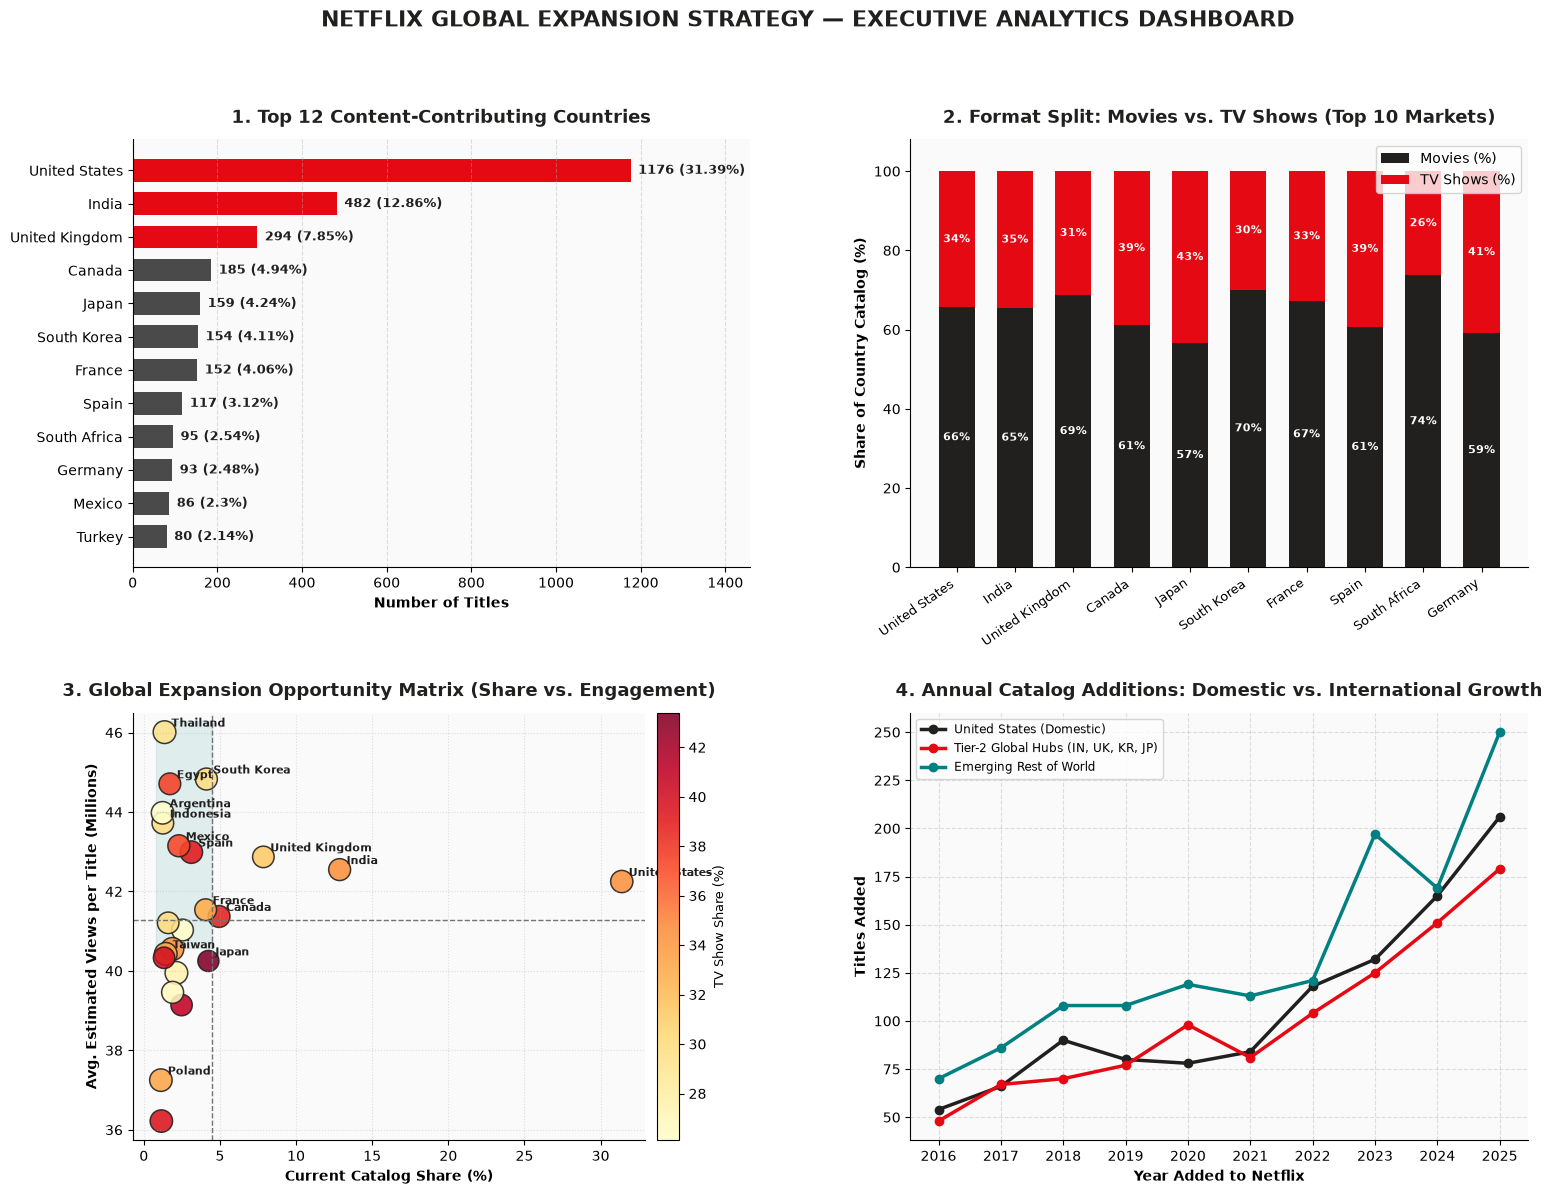

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#FAFAFA'
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
netflix_red = '#E50914'
netflix_dark = '#221F1F'
netflix_gray = '#737373'
accent_teal = '#008080'

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
plt.subplots_adjust(hspace=0.34, wspace=0.26)

ax1 = axes[0, 0]
top12 = country_summary.head(12).iloc[::-1]
colors_c1 = [netflix_red if idx in ['United States', 'India', 'United Kingdom'] else '#4A4A4A' for idx in top12.index]
bars = ax1.barh(top12.index, top12['total_titles'], color=colors_c1, edgecolor='none', height=0.68)
ax1.set_title('1. Top 12 Content-Contributing Countries', fontsize=13, fontweight='bold', color=netflix_dark, pad=12)
ax1.set_xlabel('Number of Titles', fontsize=10, fontweight='bold')
ax1.grid(axis='x', linestyle='--', alpha=0.4)
ax1.spines[['top', 'right']].set_visible(False)

for bar, (_, row) in zip(bars, top12.iterrows()):
    ax1.text(
        bar.get_width() + 18,
        bar.get_y() + bar.get_height() / 2,
        f"{int(row['total_titles'])} ({row['catalog_share_pct']}%)",
        va='center', fontsize=9, fontweight='bold', color=netflix_dark
    )
ax1.set_xlim(0, top12['total_titles'].max() * 1.24)

ax2 = axes[0, 1]
top10_mix = country_summary.head(10).copy()
top10_mix['movie_pct'] = 100 - top10_mix['tv_show_share_pct']
x_idx = np.arange(len(top10_mix))

ax2.bar(x_idx, top10_mix['movie_pct'], label='Movies (%)', color=netflix_dark, width=0.62)
ax2.bar(x_idx, top10_mix['tv_show_share_pct'], bottom=top10_mix['movie_pct'], label='TV Shows (%)', color=netflix_red, width=0.62)
ax2.set_title('2. Format Split: Movies vs. TV Shows (Top 10 Markets)', fontsize=13, fontweight='bold', color=netflix_dark, pad=12)
ax2.set_ylabel('Share of Country Catalog (%)', fontsize=10, fontweight='bold')
ax2.set_xticks(x_idx)
ax2.set_xticklabels(top10_mix.index, rotation=35, ha='right', fontsize=9)
ax2.set_ylim(0, 108)
ax2.legend(loc='upper right', frameon=True, facecolor='white')
ax2.spines[['top', 'right']].set_visible(False)

for i, (_, row) in enumerate(top10_mix.iterrows()):
    ax2.text(i, row['movie_pct'] / 2, f"{row['movie_pct']:.0f}%", ha='center', va='center', color='white', fontsize=8, fontweight='bold')
    ax2.text(i, row['movie_pct'] + row['tv_show_share_pct'] / 2, f"{row['tv_show_share_pct']:.0f}%", ha='center', va='center', color='white', fontsize=8, fontweight='bold')

ax3 = axes[1, 0]
matrix_df = country_summary[country_summary['total_titles'] >= 40].copy()

ax3.axvspan(0.8, 4.5, ymin=0.45, ymax=0.98, color=accent_teal, alpha=0.10, label='Prime Expansion Zone')
scatter = ax3.scatter(
    matrix_df['catalog_share_pct'],
    matrix_df['avg_views_millions'],
    s=(matrix_df['avg_imdb'] ** 3) * 0.85,
    c=matrix_df['tv_show_share_pct'],
    cmap='YlOrRd',
    edgecolors=netflix_dark,
    linewidth=1.1,
    alpha=0.88
)
cbar = plt.colorbar(scatter, ax=ax3, pad=0.02)
cbar.set_label('TV Show Share (%)', fontsize=9)

for country_name, row in matrix_df.iterrows():
    if row['catalog_share_pct'] > 3.5 or row['avg_views_millions'] > median_views or country_name in top_emerging_names:
        ax3.annotate(
            country_name,
            (row['catalog_share_pct'], row['avg_views_millions']),
            xytext=(5, 4), textcoords='offset points', fontsize=8, fontweight='bold', color=netflix_dark
        )

ax3.axhline(median_views, color=netflix_gray, linestyle='--', linewidth=1)
ax3.axvline(4.5, color=netflix_gray, linestyle='--', linewidth=1)
ax3.set_title('3. Global Expansion Opportunity Matrix (Share vs. Engagement)', fontsize=13, fontweight='bold', color=netflix_dark, pad=12)
ax3.set_xlabel('Current Catalog Share (%)', fontsize=10, fontweight='bold')
ax3.set_ylabel('Avg. Estimated Views per Title (Millions)', fontsize=10, fontweight='bold')
ax3.grid(True, linestyle=':', alpha=0.4)
ax3.spines[['top', 'right']].set_visible(False)

ax4 = axes[1, 1]
trend_df = geo_df[geo_df['year_added'].between(2016, 2025)].copy()
trend_df['region_group'] = np.where(
    trend_df['primary_country'] == 'United States', 'United States (Domestic)',
    np.where(trend_df['primary_country'].isin(['India', 'United Kingdom', 'South Korea', 'Japan']),
             'Tier-2 Global Hubs (IN, UK, KR, JP)', 'Emerging Rest of World')
)
yearly_pivot = trend_df.groupby(['year_added', 'region_group']).size().unstack(fill_value=0)

palette_c4 = {
    'United States (Domestic)': netflix_dark,
    'Tier-2 Global Hubs (IN, UK, KR, JP)': netflix_red,
    'Emerging Rest of World': accent_teal
}
for col in palette_c4:
    if col in yearly_pivot.columns:
        ax4.plot(yearly_pivot.index, yearly_pivot[col], marker='o', linewidth=2.5, label=col, color=palette_c4[col])

ax4.set_title('4. Annual Catalog Additions: Domestic vs. International Growth', fontsize=13, fontweight='bold', color=netflix_dark, pad=12)
ax4.set_xlabel('Year Added to Netflix', fontsize=10, fontweight='bold')
ax4.set_ylabel('Titles Added', fontsize=10, fontweight='bold')
ax4.set_xticks(yearly_pivot.index)
ax4.legend(loc='upper left', frameon=True, facecolor='white', fontsize=8.5)
ax4.grid(True, linestyle='--', alpha=0.4)
ax4.spines[['top', 'right']].set_visible(False)

fig.suptitle('NETFLIX GLOBAL EXPANSION STRATEGY — EXECUTIVE ANALYTICS DASHBOARD', fontsize=16, fontweight='bold', color=netflix_dark, y=0.98)
output_dir = Path("../figures")
output_dir.mkdir(parents=True, exist_ok=True)

file_path = output_dir / "Netflix_global_expansion_strategy.png"
fig.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()